# European contract pricing with Tree

In [2]:
import numpy as np
from scipy.optimize import minimize
from collections.abc import Callable

## Create European contract payoff

In [3]:
def european_call_payoff(S: float, K: float) -> float:
    return max(S-K, 0.0)

## Create Spot Tree

In [4]:
def create_spot_tree(spot: float, spot_mult_up: float, spot_mult_down: float, steps: int) -> list[list[float]]:
    previous_level = [spot]
    tree = [previous_level]
    for _ in range(steps):
        new_level = [s * spot_mult_down for s in previous_level]
        new_level += [previous_level[-1] * spot_mult_up]
        tree += [new_level]
        previous_level = new_level
    return tree

In [5]:
spot = 1
spot_mult_up = 1.2
spot_mult_down = 0.8
steps = 2
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
spot_tree_readable

[['1.000'], ['0.800', '1.200'], ['0.640', '0.960', '1.440']]

## Create Price Tree

In [6]:
def create_discounted_price_tree(spot_tree: list[list[float]], discount_factor: float, K: float, diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print(('%.3f' % p_up, '%.3f' % p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

In [7]:
discount_factor = 0.95
strike = 1
diag = 1
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike, diag)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("Price tree:")
price_tree_readable

risk-neutral measure: 
('0.632', '0.368')
delta: 
[['0.366'], ['-0.000', '0.827']]
Price tree:


[['0.054'], ['0.000', '0.146'], ['0.000', '0.000', '0.397']]

In [8]:
pv_up_up = 0.44*0.95*0.95
print('%.3f' % pv_up_up)

0.397


In [9]:
mid_step = 0.3971 * 0.3684210526315791
print('%.3f' % mid_step)

0.146


## Balanced Tree

In [10]:
def calcBalancedDownStep(spot_mult_up: float, discount_factor: float) -> (float, float):
    return spot_mult_up - 2 * (spot_mult_up - 1 / discount_factor)

In [11]:
print("spot_mult_up: " + str('%.3f' %spot_mult_up))
spot_mult_down_balanced = calcBalancedDownStep(spot_mult_up, discount_factor)
print("spot_mult_down: " + str('%.3f' %spot_mult_down_balanced))
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down_balanced, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
print("spot_tree: " + str(spot_tree_readable))
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike, 1)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("price tree: " + str(price_tree_readable))

spot_mult_up: 1.200
spot_mult_down: 0.905
spot_tree: [['1.000'], ['0.905', '1.200'], ['0.820', '1.086', '1.440']]
risk-neutral measure: 
('0.500', '0.500')
delta: 
[['0.674'], ['0.292', '0.903']]
price tree: [['0.138'], ['0.039', '0.237'], ['0.000', '0.078', '0.397']]


## Delta is close to 0.5 for At The Money Forward option

In [12]:
strike_ATMF = 1/0.95**2
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike_ATMF, 1)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("price tree:")
price_tree_readable

risk-neutral measure: 
('0.500', '0.500')
delta: 
[['0.508'], ['-0.000', '0.847']]
price tree:


[['0.075'], ['0.000', '0.150'], ['0.000', '0.000', '0.300']]

## Barrier options

In [13]:
def up_and_out(B: float) -> Callable[[float], float]:
    def knock_multiplier(s: float) -> float:
        return 1.0 if (s < B) else 0.0
    return knock_multiplier

In [14]:
def create_discounted_price_tree_ko(spot_tree: list[list[float]], discount_factor: float, K: float, ko_function: Callable[[float], float], diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print((p_up, p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K) * ko_function(spot)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            continuation_value_tree[step][i] *= ko_function(spot_tree[step][i])
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
                delta_tree[step][i] *= ko_function(spot_tree[step][i])
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

In [15]:
# create spot tree
spot = 1
maturity = 1 # years
steps_per_year = 7
steps = steps_per_year * maturity
discount_factor = 0.95 ** (1./steps_per_year) # discount factors have to be scaled to keep interest rate fixed
spot_mult_up = np.exp((0.05 - 0.5 * 0.1 ** 2) / steps_per_year + 0.1 * np.sqrt(1./steps_per_year)) # step sizes are scaled as well
spot_mult_down = calcBalancedDownStep(spot_mult_up, discount_factor)
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
spot_tree_readable

[['1.000'],
 ['0.969', '1.045'],
 ['0.940', '1.013', '1.092'],
 ['0.911', '0.982', '1.059', '1.142'],
 ['0.883', '0.952', '1.027', '1.107', '1.194'],
 ['0.856', '0.923', '0.996', '1.073', '1.157', '1.247'],
 ['0.830', '0.895', '0.965', '1.041', '1.122', '1.209', '1.304'],
 ['0.805', '0.868', '0.936', '1.009', '1.088', '1.173', '1.264', '1.363']]

In [16]:
# create price tree
strike = 1
barrier = 1.2
barrier_condition = up_and_out(barrier)
diag = 1
price_tree = create_discounted_price_tree_ko(spot_tree, discount_factor, strike, barrier_condition, diag)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("Price tree:")
price_tree_readable

risk-neutral measure: 
(np.float64(0.5), np.float64(0.5))
delta: 
[['0.246'], ['0.386', '0.113'], ['0.378', '0.389', '-0.145'], ['0.181', '0.555', '0.229', '-0.490'], ['0.031', '0.317', '0.768', '-0.273', '-0.683'], ['-0.000', '0.060', '0.552', '0.957', '-1.410', '-0.000'], ['-0.000', '-0.000', '0.114', '0.950', '0.950', '-0.000', '-0.000']]
Price tree:


[['0.044'],
 ['0.035', '0.054'],
 ['0.021', '0.049', '0.058'],
 ['0.007', '0.034', '0.064', '0.052'],
 ['0.001', '0.014', '0.055', '0.073', '0.031'],
 ['0.000', '0.002', '0.025', '0.085', '0.062', '0.000'],
 ['0.000', '0.000', '0.004', '0.046', '0.124', '0.000', '0.000'],
 ['0.000', '0.000', '0.000', '0.008', '0.083', '0.164', '0.000', '0.000']]

## Q: How would you model continuous barrier better?

## HW: calibrator


In [17]:
from scipy.optimize import minimize
from scipy.stats import norm
import numpy as np

target BSM price = 0.094134
steps=   1  U=1.194002  D=0.866907  tree price=0.094134
steps=   2  U=1.173596  D=0.856630  tree price=0.094134
steps=   3  U=1.117326  D=0.902774  tree price=0.094134
steps=   5  U=1.091587  D=0.920450  tree price=0.094134
steps=  10  U=1.067107  D=0.938902  tree price=0.094134
steps=  20  U=1.046394  D=0.956608  tree price=0.094134
steps=  50  U=1.028873  D=0.972327  tree price=0.094134
steps= 100  U=1.020279  D=0.980321  tree price=0.094134


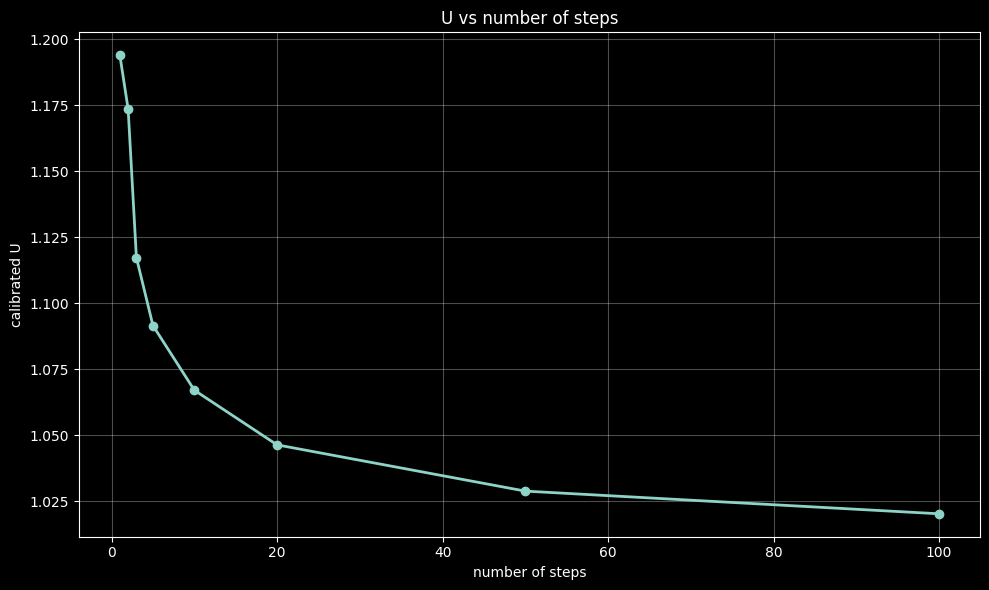

In [31]:

import matplotlib.pyplot as plt
def calibrator(target_price: float, S: float, K: float, df: float, steps: int) -> float:
    """Up step U for which the balanced tree prices a European call at target_price
    (spot S, strike K, per-step discount factor df)."""
    U_min, U_max = 0.99/ df, 2.0 / df - 0.01

    def tree_price(U):
        D = calcBalancedDownStep(U, df)
        spot_tree = create_spot_tree(spot, U, D, steps)
        price_tree = create_discounted_price_tree(spot_tree, df, K)
        return S * price_tree[0][0]

    p_lo, p_hi = tree_price(U_min), tree_price(U_max)
    grid = np.linspace(U_min, U_max, 100)
    prices = np.array([tree_price(u) for u in grid])
    i = min(max(int(np.searchsorted(prices, target_price)), 1), len(grid) - 1)
    a, b = grid[i - 1], grid[i]

    result = minimize(
        lambda x: (tree_price(x[0]) - target_price) ** 2,
        x0=[0.5 * (a + b)],
        # x0=1.1,
        method="Nelder-Mead",
        bounds=[(U_min, U_max)],
        options=dict(initial_simplex=[[a], [b]], xatol=1e-12, fatol=1e-24),
    )
    if not result.success:
        raise RuntimeError(result.message)
    return float(result.x[0])


def bs_call(S, K, r, T, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d1 - sigma * np.sqrt(T))


def tree_call_price(S, K, df, steps, U):
    D = calcBalancedDownStep(U, df)
    return S * create_discounted_price_tree(create_spot_tree(1.0, U, D, steps), df, K / S)[0][0]


S0, K0, r, T, sigma = 1.0, 1.0, 0.03, 1.0, 0.2
target = bs_call(S0, K0, r, T, sigma)
print(f"target BSM price = {target:.6f}")
ns = [1, 2, 3, 5, 10, 20, 50, 100] #same contract with different number of steps
Us = []
for n in ns:
    df = np.exp(-r * T / n) #scale df
    U = calibrator(target, S0, K0, df, n)
    Us.append(U)
    print(f"steps={n:4d}  U={U:.6f}  D={calcBalancedDownStep(U, df):.6f}  "
          f"tree price={tree_call_price(S0, K0, df, n, U):.6f}")

# Plot: U after calibrator vs number of steps
x_plot = [float(s) for s in ns]
y_plot = Us

plt.figure(figsize=(10, 6))
plt.plot(x_plot, y_plot, marker='o', linewidth=2)

plt.title('U vs number of steps')
plt.xlabel('number of steps')
plt.ylabel('calibrated U')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
# 1-step tree calibration for different contracts

steps = 1
expiries = [0.25, 0.5, 1.0, 2.0, 3.0]
strikes = [float(k) for k in np.arange(0.8, 1.3, 0.1)]

U_results = np.full((len(expiries), len(strikes)), np.nan)
errors = np.full_like(U_results, np.nan)

for i, T_i in enumerate(expiries):
    df = np.exp(-r * T_i)

    for j, K_i in enumerate(strikes):
        target = bs_call(S0, K_i, r, T_i, sigma)

        U = calibrator(target, S0, K_i, df, steps)
        tree_price = tree_call_price(S0, K_i, df, steps, U)

        U_results[i, j] = U
        errors[i, j] = abs(tree_price - target)

        print(
            f"T={T_i:.2f} | K={K_i:.2f} | "
            f"U={U:.6f} | "
            f"target BSM price={target:.6f} | "
            f"tree price={tree_price:.6f} | "
        )

T=0.25 | K=0.80 | U=1.215701 | target BSM price=0.206297 | tree price=0.206297 | 
T=0.25 | K=0.90 | U=1.127392 | target BSM price=0.112847 | tree price=0.112847 | 
T=0.25 | K=1.00 | U=1.087808 | target BSM price=0.043576 | tree price=0.043576 | 
T=0.25 | K=1.10 | U=1.121991 | target BSM price=0.010913 | tree price=0.010913 | 
T=0.25 | K=1.20 | U=1.203569 | target BSM price=0.001771 | tree price=0.001771 | 
T=0.50 | K=0.80 | U=1.235064 | target BSM price=0.214293 | tree price=0.214293 | 
T=0.50 | K=0.90 | U=1.159855 | target BSM price=0.127993 | tree price=0.127993 | 
T=0.50 | K=1.00 | U=1.129346 | target BSM price=0.063710 | tree price=0.063710 | 
T=0.50 | K=1.10 | U=1.153028 | target BSM price=0.026119 | tree price=0.026119 | 
T=0.50 | K=1.20 | U=1.218097 | target BSM price=0.008914 | tree price=0.008914 | 
T=1.00 | K=0.80 | U=1.278625 | target BSM price=0.232240 | tree price=0.232240 | 
T=1.00 | K=0.90 | U=1.217982 | target BSM price=0.154292 | tree price=0.154292 | 
T=1.00 | K=1.00 

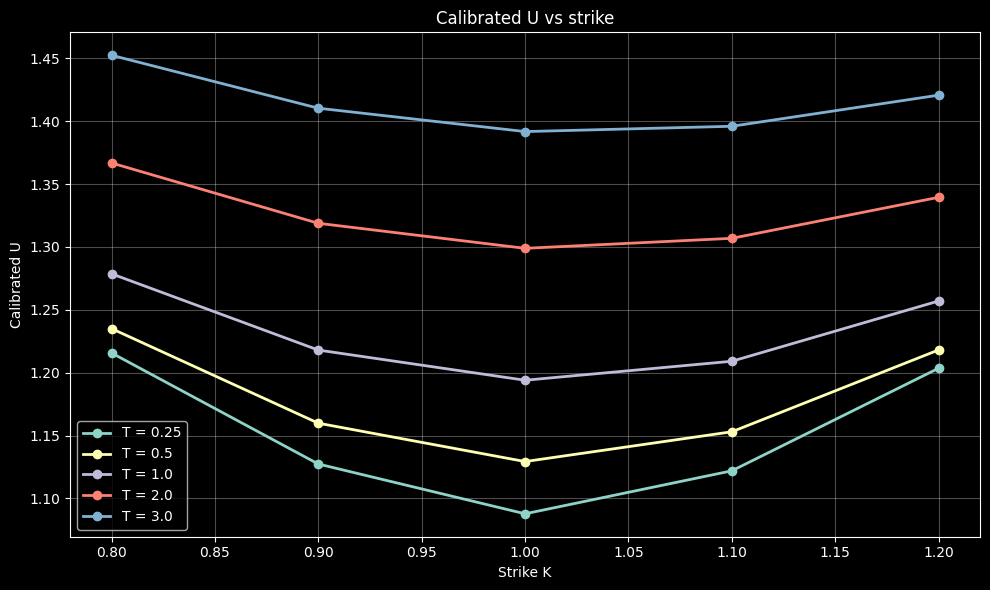

In [34]:
plt.figure(figsize=(10, 6))

for i, T_i in enumerate(expiries):
    plt.plot(
        strikes,
        U_results[i, :],
        marker='o',
        linewidth=2,
        label=f'T = {T_i}'
    )

plt.title('Calibrated U vs strike')
plt.xlabel('Strike K')
plt.ylabel('Calibrated U')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

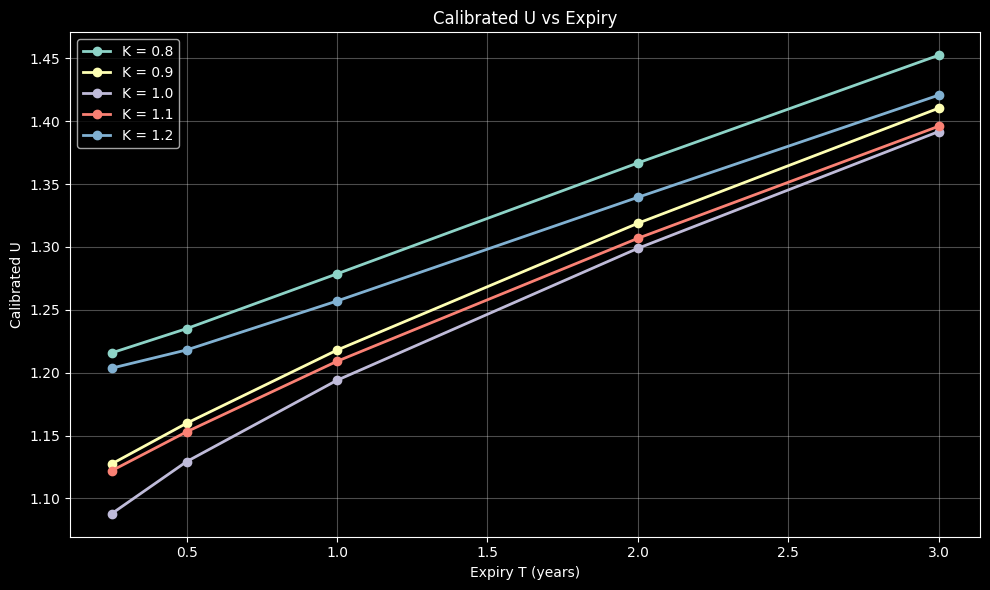

In [35]:
plt.figure(figsize=(10, 6))

for j, K_i in enumerate(strikes):
    plt.plot(
        expiries,
        U_results[:, j],
        marker='o',
        linewidth=2,
        label=f'K = {K_i}'
    )

plt.title('Calibrated U vs Expiry')
plt.xlabel('Expiry T (years)')
plt.ylabel('Calibrated U')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()